Per-nucleus transcriptomics preprocessing, based on the [10x Genomics segmentation guide](https://www.10xgenomics.com/analysis-guides/segmentation-visium-hd).
Cell segmentation is done beforehand with `NucleiSegmentation.py` (`01_preprocessing/histology/unimodel/notebooks/scripts`).

**Scripts instead of this notebook:** the steps are slow and need a lot of RAM on large slides, so for whole samples use
- `scripts/preprocess.py --sample X --unit cell`: loading, spatial join, count summation, QC, clustering, geometry and patch assignment (cutoffs via `--umi-cutoff` and `--nuclei-area-cutoff`)
- `scripts/get_svg.py --sample X --unit cell`: spatially variable genes

This notebook is meant for exploring cutoffs and plots. The merge cells at the end exist only here.


In [1]:
import anndata
import gc
import geopandas as gpd
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import pickle
import scanpy as sc
import squidpy as sq

from csbdeep.utils import normalize
from matplotlib.colors import ListedColormap
from scipy import sparse
from shapely.geometry import Polygon, Point
from stardist.models import StarDist2D
from tifffile import imread, imwrite

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
2026-08-25 15:55:35.984704: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-25 15:55:36.006383: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX_VNNI FMA, in other operations, rebuild TensorF

# Helper Functions and Variables
Plotting functions and paths for the next steps.


In [2]:
# sample and unit
sample = "CRC_P11mm_2_cut"  # adapt as needed
bin_size = "002um"
dir_cellseg = "cell_seg_stardist"  # segmentation method
f_wsi = 'Visium_HD_Human_Colon_Cancer_P2_tissue_image.btf'  # adapt as needed

# directories
basedir = Path("../../data")
dir_base_input = basedir / sample / "input"
dir_base_output = basedir / sample / f"output/binned_outputs/square_{bin_size}"
dir_result_output = basedir / sample / "01_preprocessing" / dir_cellseg / bin_size
dir_custom_binning = dir_result_output / "custom_binning"
dir_result_output.mkdir(parents=True, exist_ok=True)
dir_custom_binning.mkdir(parents=True, exist_ok=True)

In [3]:
# nuclei area histograms, all and below cutoff
def plot_nuclei_area(gdf,area_cut_off):
    fig, axs = plt.subplots(1, 2, figsize=(15, 4))
    axs[0].hist(gdf['area'], bins=50, edgecolor='black')
    axs[0].set_title('Nuclei Area')

    axs[1].hist(gdf[gdf['area'] < area_cut_off]['area'], bins=50, edgecolor='black')
    axs[1].set_title('Nuclei Area Filtered:'+str(area_cut_off))

    plt.tight_layout()
    plt.show()

# total UMI boxplots, all and above cutoff
def total_umi(adata_, cut_off):
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))

    # all
    axs[0].boxplot(adata_.obs["total_counts"], vert=False, widths=0.7, patch_artist=True, boxprops=dict(facecolor='skyblue'))
    axs[0].set_title('Total Counts')

    # above cutoff
    axs[1].boxplot(adata_.obs["total_counts"][adata_.obs["total_counts"] > cut_off], vert=False, widths=0.7, patch_artist=True, boxprops=dict(facecolor='skyblue'))
    axs[1].set_title('Total Counts > ' + str(cut_off))

    # hide y axis
    for ax in axs:
        ax.get_yaxis().set_visible(False)

    plt.tight_layout()
    plt.show()


Tissue bounding box (x min, y min, x max, y max) from the tissue positions and the StarDist nucleus polygons as `gdf` (one polygon and id per nucleus).


In [8]:
# bounding box of the tissue area (x min, y min, x max, y max)
tissue_path = dir_base_output / "spatial/tissue_positions.parquet" # bin ids with pixel and array coordinates
tissuepositions = pd.read_parquet(tissue_path)
col = "pxl_col_in_fullres"
row = "pxl_row_in_fullres"
x_min = math.floor(tissuepositions.loc[tissuepositions[col] > 0, col].min())
x_max = math.ceil(tissuepositions.loc[tissuepositions[col] > 0, col].max())
y_min = math.floor(tissuepositions.loc[tissuepositions[row] > 0, row].min())
y_max = math.ceil(tissuepositions.loc[tissuepositions[row] > 0, row].max())

# StarDist polygons
with open((dir_result_output / "polys_FullSection.pckl"), "rb") as f:
    polys = pickle.load(f)

# polygons from coordinates, (row, col) swapped to (x, y)
geometries = []
for nuclei in range(len(polys['coord'])):
    coords = [(y, x) for x, y in zip(polys['coord'][nuclei][0], polys['coord'][nuclei][1])]
    geometries.append(Polygon(coords))

# one polygon and id per nucleus
gdf = gpd.GeoDataFrame(geometry=geometries)
gdf["id"] = [f"ID_{i+1}" for i in range(len(gdf))]
print(gdf.head())

# single color cmap for plotting
cmap=ListedColormap(['grey'])

# free memory
del tissuepositions, polys, geometries
gc.collect()

                                            geometry    id
0  POLYGON ((15096.911 2254.000, 15094.153 2257.2...  ID_1
1  POLYGON ((51702.874 3926.000, 51700.444 3931.2...  ID_2
2  POLYGON ((53399.820 2424.000, 53398.852 2426.5...  ID_3
3  POLYGON ((53027.689 2900.000, 53027.053 2901.4...  ID_4
4  POLYGON ((51833.389 3786.000, 51835.355 3789.4...  ID_5


0

# Binning Visium HD Gene Expression Data
Loads the 2 µm counts (`filtered_feature_bc_matrix.h5`) and bin positions (`tissue_positions.parquet`) and builds a GeoDataFrame of the bin points.

**Script:** this step up to the clustering is done by `scripts/preprocess.py --unit cell`, it handles millions of 2 µm bins.


In [9]:
# memory saving version
import gc
from pathlib import Path
import pandas as pd
import geopandas as gpd
import scanpy as sc

# counts
f_raw_h5 = dir_base_output / 'filtered_feature_bc_matrix.h5'
adata = sc.read_10x_h5(f_raw_h5)

# bin positions, only needed columns
tissue_position_file = dir_base_output / 'spatial/tissue_positions.parquet'
cols_to_load = ['barcode', 'pxl_row_in_fullres', 'pxl_col_in_fullres', 'in_tissue']

# barcode may be index or column
df_tissue_positions = pd.read_parquet(
    tissue_position_file,
    columns=[c for c in cols_to_load if c != 'barcode']
)

if 'barcode' in df_tissue_positions.columns:
    df_tissue_positions = df_tissue_positions.set_index('barcode')

# positions into obs
adata.obs = adata.obs.join(df_tissue_positions, how='left')
adata.obs['pxl_row_in_fullres'] = adata.obs['pxl_row_in_fullres'].astype('float32')
adata.obs['pxl_col_in_fullres'] = adata.obs['pxl_col_in_fullres'].astype('float32')

# coordinates into obsm for scanpy
spatial_cols = ['pxl_row_in_fullres', 'pxl_col_in_fullres']
adata.obsm['spatial'] = adata.obs[spatial_cols].to_numpy()

print("creating gdf")
# bin points as geodataframe
gdf_coordinates = gpd.GeoDataFrame(
    adata.obs[spatial_cols],
    geometry=gpd.points_from_xy(
        adata.obs['pxl_col_in_fullres'],
        adata.obs['pxl_row_in_fullres']
    ),
    crs=None
)

# free memory
del df_tissue_positions
gc.collect()

anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.
anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


creating gdf


87

In [10]:
# older loading variant, overwrites adata and gdf_coordinates of the cell above
f_raw_h5 = dir_base_output / 'filtered_feature_bc_matrix.h5'
adata = sc.read_10x_h5(f_raw_h5)

# bin positions, barcode as index
tissue_position_file = dir_base_output / 'spatial/tissue_positions.parquet'
df_tissue_positions=pd.read_parquet(tissue_position_file)
df_tissue_positions = df_tissue_positions.set_index('barcode')

# index copy to check joins
df_tissue_positions['index']=df_tissue_positions.index

# positions into obs
adata.obs = pd.merge(adata.obs, df_tissue_positions, left_index=True, right_index=True)

# bin points as geodataframe
geometry = [Point(xy) for xy in zip(df_tissue_positions['pxl_col_in_fullres'], df_tissue_positions['pxl_row_in_fullres'])]
gdf_coordinates = gpd.GeoDataFrame(df_tissue_positions, geometry=geometry)

del f_raw_h5, df_tissue_positions
gc.collect()

anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.
anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


107

Spatial join of bins to nuclei: bins in exactly one nucleus polygon are kept, bins in overlapping polygons are dropped.
**Output** `filtered_custom_bins.h5ad`: one row per kept bin, `.X` counts, `.obs` with pixel position, `in_tissue`, array position and nucleus `id`.


In [ ]:
# bin in nucleus polygon, barcode stays index
result_spatial_join = gpd.sjoin(gdf_coordinates, gdf, how='left', predicate='within')

# bin inside any polygon
result_spatial_join['is_within_polygon'] = ~result_spatial_join['index_right'].isna()

# barcodes in several overlapping polygons (duplicated index)
overlapping_barcodes = result_spatial_join.index[result_spatial_join.index.duplicated()].unique()

# keep bins in exactly one polygon
valid_mask = (
    result_spatial_join['is_within_polygon'] &
    ~result_spatial_join.index.isin(overlapping_barcodes)
)
barcodes_in_one_polygon = result_spatial_join[valid_mask]

# subset counts to these bins
filtered_adata = adata[adata.obs_names.isin(barcodes_in_one_polygon.index)].copy()

# nucleus id per bin
cols_to_add = ['id', 'is_within_polygon']
filtered_adata.obs = filtered_adata.obs.join(barcodes_in_one_polygon[cols_to_add], how='left')
filtered_adata.obs["Slide_ID"] = sample

# save
filtered_adata.write(dir_custom_binning / "filtered_custom_bins.h5ad")

# free memory
del result_spatial_join, barcodes_in_one_polygon
gc.collect()

anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


Counts of all bins in a nucleus are summed.
**Output** `nuclei_grouped_UMI_count.h5ad`: one row per nucleus (`.obs`: `id`, `Slide_ID`), `.X` summed UMI counts per gene, `.var` gene ids, feature types and genome.


In [ ]:
# bins grouped by nucleus id
groupby_object = filtered_adata.obs.groupby(['id'], observed=True)

# counts of the bins
counts = filtered_adata.X

# matrix size, nuclei x genes
N_groups = groupby_object.ngroups
N_genes = counts.shape[1]

# sparse matrix for the summed counts
summed_counts = sparse.lil_matrix((N_groups, N_genes))

# nucleus ids and row counter
polygon_id = []
row = 0

# sum counts of all bins in each nucleus
for polygons, idx_ in groupby_object.indices.items():
    summed_counts[row] = counts[idx_].sum(0)
    row += 1
    polygon_id.append(polygons)

# csr matrix and obs table
summed_counts = summed_counts.tocsr()
obs_df = pd.DataFrame(polygon_id, columns=['id'], index=polygon_id)

# nucleus polygons in pixels, used later for the patch overlay
obs_df = obs_df.merge(gdf[['id', 'geometry']], on='id', how='left')

grouped_filtered_adata = anndata.AnnData(X=summed_counts, obs=obs_df, var=filtered_adata.var)
grouped_filtered_adata.obs["Slide_ID"] = sample


# geometry only stays in memory, cannot be written to h5ad
geodata = grouped_filtered_adata.obs["geometry"]
grouped_filtered_adata.obs = grouped_filtered_adata.obs.drop(columns=["geometry"])
grouped_filtered_adata.write(dir_custom_binning / "nuclei_grouped_UMI_count.h5ad")
grouped_filtered_adata.obs["geometry"] = geodata

# free memory
del groupby_object, N_groups, polygon_id, summed_counts, obs_df
gc.collect()

aligned_df.py (67): Transforming to str index.
anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


# Nuclei Binning Results
Removes very large nuclei (likely aggregates or artifacts) and nuclei with too few UMI counts. Optional, the cutoffs depend on the sample.


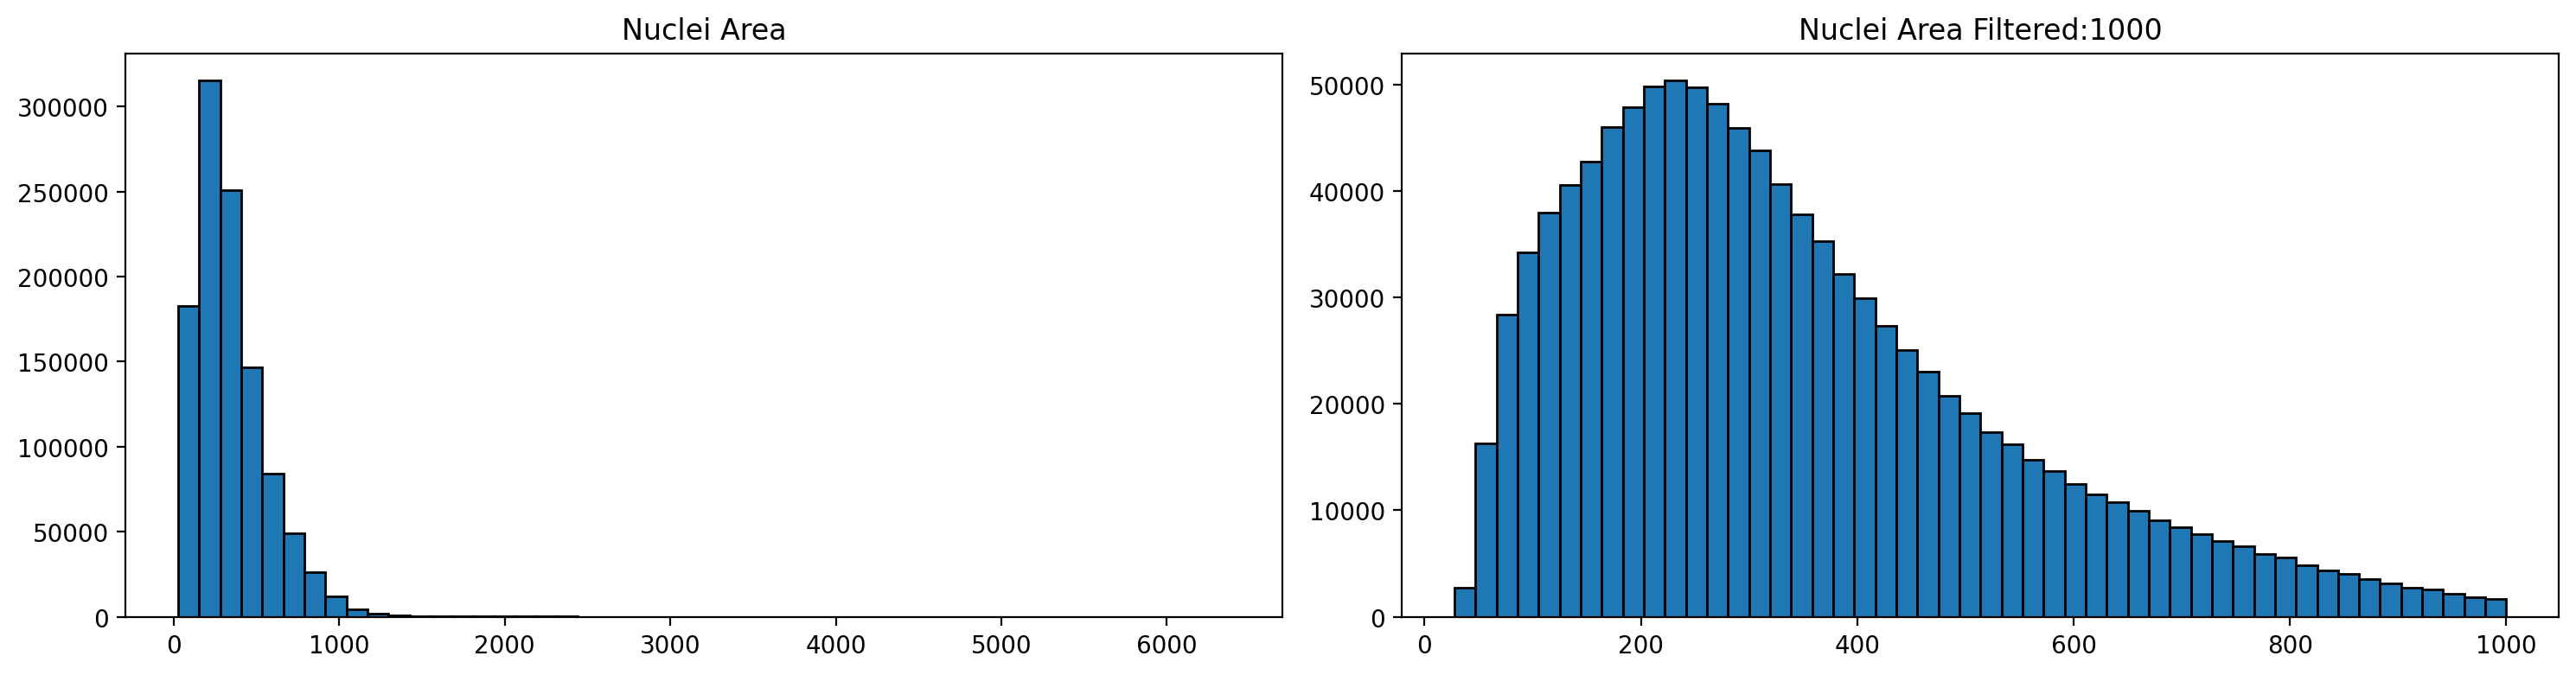

In [17]:
# nucleus area in pixels
gdf['area'] = gdf['geometry'].area

# qc metrics of the unfiltered nuclei
sc.pp.calculate_qc_metrics(grouped_filtered_adata, inplace=True)

# area distribution before and after the cutoff
plot_nuclei_area(gdf=gdf,area_cut_off=1000)

x-axis: nucleus area  
y-axis: no. of nuclei with that area

Area cutoff of 1000 chosen from this distribution. Next, the total UMI distribution.


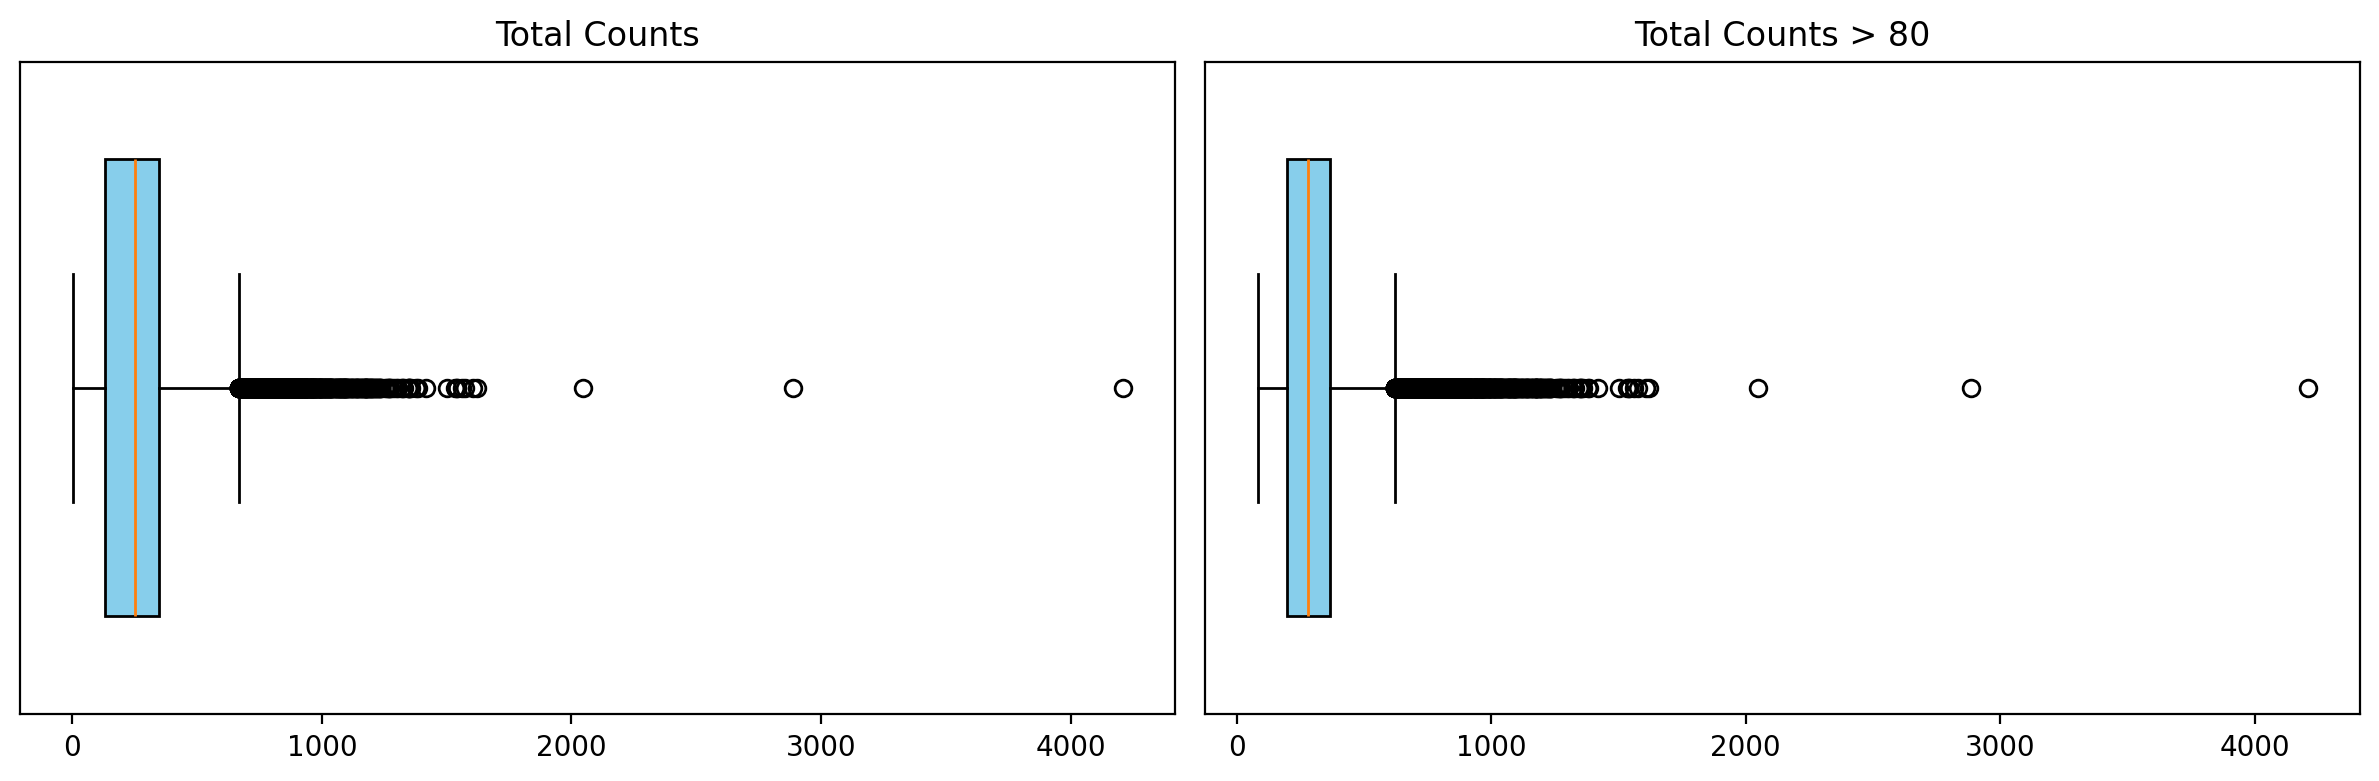

In [22]:
# UMI distribution before and after the cutoff
cutoff = 80
total_umi(grouped_filtered_adata, cutoff)

Cutoffs may need adjustment for other datasets, check them against the clustering. The next cell keeps nuclei with area < 1000 and total counts > 80.


In [21]:
# cutoffs
area_cutoff = 1000
umi_cutoff = cutoff

n_total = grouped_filtered_adata.n_obs

# masks per filter
mask_area = grouped_filtered_adata.obs['id'].isin(gdf[gdf['area'] < area_cutoff].id)
mask_count = grouped_filtered_adata.obs['total_counts'] > umi_cutoff

# passing and failing per filter
n_pass_area = mask_area.sum()
n_pass_count = mask_count.sum()
n_fail_area = (~mask_area).sum()
n_fail_count = (~mask_count).sum()

# both filters combined
mask_both = mask_area & mask_count
n_pass_both = mask_both.sum()

# reason for removal
removed_area_only   = (~mask_area &  mask_count).sum()  # too large, UMI fine
removed_count_only  = ( mask_area & ~mask_count).sum()  # UMI too low, area fine
removed_both        = (~mask_area & ~mask_count).sum()  # too large and UMI too low

print(f"Total nuclei before filtering: {n_total}")
print(f"  Removed for area >= {area_cutoff} (large/aggregated nuclei): {n_fail_area} ({n_fail_area/n_total:.1%})")
print(f"  Removed for total_counts <= {umi_cutoff} (low UMI):          {n_fail_count} ({n_fail_count/n_total:.1%})")
print()
print(f"  Removed by area filter ONLY:        {removed_area_only}")
print(f"  Removed by UMI filter ONLY:         {removed_count_only}")
print(f"  Removed by BOTH filters:            {removed_both}")
print()
print(f"Nuclei remaining after both filters: {n_pass_both} ({n_pass_both/n_total:.1%})")

# filtered adata
count_area_filtered_adata = grouped_filtered_adata[mask_area & mask_count, :]
count_area_filtered_adata.var_names_make_unique()

# qc metrics of the filtered nuclei
sc.pp.calculate_qc_metrics(count_area_filtered_adata, inplace=True)

Total nuclei before filtering: 107176
  Removed for area >= 500 (large/aggregated nuclei): 1582 (1.5%)
  Removed for total_counts <= 100 (low UMI):          16651 (15.5%)

  Removed by area filter ONLY:        1419
  Removed by UMI filter ONLY:         16488
  Removed by BOTH filters:            163

Nuclei remaining after both filters: 89106 (83.1%)


anndata.py (1820): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


Normalize, log1p, HVG, PCA, neighbors and Leiden clustering (`normalize_and_cluster`). The Leiden resolution (0.2) may need adjustment for other datasets.


In [ ]:
import sys
sys.path.insert(0, str(Path("../..").resolve()))
from functions.transcriptomics import normalize_and_cluster

# normalize, log1p, HVG, PCA, neighbors, leiden (resolution 0.2)
normalize_and_cluster(count_area_filtered_adata)

# geometry only stays in memory, cannot be written to h5ad
geodata = count_area_filtered_adata.obs["geometry"]
count_area_filtered_adata.obs = count_area_filtered_adata.obs.drop(columns=["geometry"])
sc.write(dir_custom_binning / "count_area_filtered_adata.h5ad", count_area_filtered_adata)
count_area_filtered_adata.obs["geometry"] = geodata

**Output** `count_area_filtered_adata.h5ad`: filtered nuclei with clusters.
`nuclei_geometry.parquet` additionally stores polygon, centroid and interior centroid of these nuclei.


In [24]:
# geometry table of the filtered nuclei
nuclei_geometry = gpd.GeoDataFrame(
    count_area_filtered_adata.obs[["id", "geometry", "Slide_ID"]].copy(),
    geometry="geometry"
)

# keep the unnamed adata index
nuclei_geometry.index = count_area_filtered_adata.obs.index
nuclei_geometry.index.name = None

# centroid and interior centroid
if "centroid" not in nuclei_geometry.columns:
    nuclei_geometry["centroid"] = nuclei_geometry.geometry.centroid

if "interior_centroid" not in nuclei_geometry.columns:
    nuclei_geometry["interior_centroid"] = nuclei_geometry.geometry.representative_point()

# save
nuclei_geometry.to_parquet(dir_custom_binning / "nuclei_geometry.parquet")

### Spatially Variable Genes
Moran's I on a Delaunay graph of the nucleus centroids. Genes with FDR < 0.05 and I > 0.1 are marked in `.var['spatially_variable']`, results are written back to `count_area_filtered_adata.h5ad`. Grid bins are handled in `BinPreprocessing.ipynb`.

**Script:** very slow (1000 permutations per gene), use `scripts/get_svg.py --sample X --unit cell`. `--n-jobs` sets the parallel workers, lower it if workers run out of memory.


In [25]:
# load geometry and filtered nuclei
nuclei_geometry = gpd.read_parquet(dir_custom_binning / "nuclei_geometry.parquet")
count_area_filtered_adata = sc.read_h5ad(dir_custom_binning / "count_area_filtered_adata.h5ad")

# centroids if missing
if "centroid" not in nuclei_geometry.columns:
    nuclei_geometry["centroid"] = nuclei_geometry.geometry.centroid

if "interior_centroid" not in nuclei_geometry.columns:
    nuclei_geometry["interior_centroid"] = nuclei_geometry.geometry.representative_point()

# geometry in the nucleus order of the adata
geometry_aligned = nuclei_geometry.set_index('id').reindex(count_area_filtered_adata.obs['id'])
assert geometry_aligned['centroid'].isnull().sum() == 0, "Some nucleus IDs didn't match!"
centroids = geometry_aligned['centroid']

# centroid coordinates into obsm spatial
count_area_filtered_adata.obsm['spatial'] = np.column_stack([centroids.x.values, centroids.y.values])

# free memory
del nuclei_geometry, geometry_aligned, centroids
gc.collect()

57703

In [26]:
# spatial coordinates as numpy array
count_area_filtered_adata.obsm["spatial"] = np.asarray(count_area_filtered_adata.obsm["spatial"])

print("Building spatial neighborhood graph...")
# delaunay graph on the nucleus centroids
sq.gr.spatial_neighbors(count_area_filtered_adata,
                        coord_type="generic",
                        delaunay=True,)

# moran's I per gene
print("Building spatial autocorr...")
sq.gr.spatial_autocorr(count_area_filtered_adata,
                       mode="moran",
                       genes=count_area_filtered_adata.var_names,
                       n_perms=1000,
                       n_jobs=20,) # adapt to machine


# moran's I and FDR into var, aligned by gene name
moran_res = count_area_filtered_adata.uns['moranI']
print("Got morans I")

count_area_filtered_adata.var['moranI'] = moran_res['I'].reindex(count_area_filtered_adata.var_names)
count_area_filtered_adata.var['moranI_pval_fdr'] = moran_res['pval_sim_fdr_bh'].reindex(count_area_filtered_adata.var_names)

# spatially variable genes by threshold
count_area_filtered_adata.var['spatially_variable'] = (
    (count_area_filtered_adata.var['moranI_pval_fdr'] < 0.05) &
    (count_area_filtered_adata.var['moranI'] > 0.1)   # adjust to distribution of I
)
print(count_area_filtered_adata.var['spatially_variable'].sum(), "spatially variable genes for person ", sample)

# overwrite the canonical file, merge reads moranI from it
count_area_filtered_adata.write(dir_custom_binning / "count_area_filtered_adata.h5ad")
print("unique var_names in count_area_filtered_adata: ", count_area_filtered_adata.var_names.is_unique)

Building spatial neighborhood graph...
Building spatial autocorr...


_common.py (62): 182 variables were constant, will return nan for these.
  0%|          | 0/1000 [00:00<?, ?/s]/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-package

KeyboardInterrupt: 

# Assigning bins/nuclei to patches

**Goal** Assign each nucleus to the histology patch it overlaps most.
**Inputs** per sample `filtered_WSI_patch_embeddings.h5ad` (patch positions), `nuclei_geometry.parquet` (nucleus polygons) and `count_area_filtered_adata.h5ad`.
**Output** `count_area_filtered_adata.h5ad`, overwritten with an additional `Patch_ID` column.

Functions from `functions/transcriptomics.py` (shared with `preprocess.py`):
- `assign_cells_to_patches`: overlap of nucleus and patch polygons of one slide, returns {nucleus_ID: patch_ID}.
- `add_patch_ids_to_nuclei`: merges the geometry, adds `Patch_ID` and removes the geometry columns again.

**Script:** `scripts/preprocess.py --unit cell` already does this step for one sample at the end of its run.


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("../..").resolve()))
import geopandas as gpd
import scanpy as sc
from functions.transcriptomics import add_patch_ids_to_nuclei

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [ ]:
# variables
bin_size = "002um"
patch_size = 224
cellseg_dir = "cell_seg_stardist"
basedir = Path("../../data")

# filenames
f_patch_embeddings = "filtered_WSI_patch_embeddings.h5ad"
f_nuclei_adata = "count_area_filtered_adata.h5ad"
f_nuclei_geometry = "nuclei_geometry.parquet"

# all samples, same discovery as the merge below
exclude_dirs = ["new", "archived"]
samples = [p.name for p in basedir.iterdir() if (p.is_dir() and p.name != "combined" and p.name not in exclude_dirs)]
print("Samples to assign patches for:", samples)

In [ ]:
for sample in samples:
    dir_trans = basedir / sample / "01_preprocessing" / cellseg_dir / bin_size / "custom_binning"
    dir_histology = basedir / sample / "01_preprocessing/unimodel/metadata"

    # skip samples without patch embeddings or nuclei file
    if not (dir_histology / f_patch_embeddings).exists():
        print(f"Skipping {sample}: no {f_patch_embeddings} yet.")
        continue
    if not (dir_trans / f_nuclei_adata).exists():
        print(f"Skipping {sample}: no {f_nuclei_adata} yet.")
        continue

    print(f"\n=== {sample} ===")
    adata_patches = sc.read_h5ad(dir_histology / f_patch_embeddings)
    nuclei_geometry = gpd.read_parquet(dir_trans / f_nuclei_geometry)
    nuclei_adata = sc.read_h5ad(dir_trans / f_nuclei_adata)

    # geometry merged in, Patch_ID added, geometry removed again
    nuclei_adata = add_patch_ids_to_nuclei(nuclei_adata, nuclei_geometry, adata_patches.obs, sample, patch_size)

    # overwrites count_area_filtered_adata.h5ad
    nuclei_adata.write(dir_trans / f_nuclei_adata)
    print(f"Wrote {dir_trans / f_nuclei_adata}")

    del nuclei_adata, adata_patches, nuclei_geometry

# Merging the output
Run after all samples are processed. Merges the per-sample files (nuclei counts, bins, filtered nuclei, geometry) into the `combined` folder.
Only sample folders created by the segmentation (named like the slides) should be in the output directory, other folders belong into `exclude_dirs`.

**Script:** none, merging is only available in this notebook. It loads the files of all samples.


In [1]:
import sys
import anndata as ad
import geopandas as gpd
import numpy as np
import pandas as pd
from pathlib import Path
import scanpy as sc
import gc

sys.path.insert(0, str(Path("../..").resolve()))
from functions.merge import merge_anndatas, merge_parquet

bin_size = "002um"
basedir = Path("../../data")

# path templates for the merge
dir_custom_binning = "{basedir}/{sample}/01_preprocessing/cell_seg_stardist/{bin_size}/custom_binning"
path_template_custom_binning = dir_custom_binning + "/{filename}"

print([p.name for p in basedir.iterdir() if (p.is_dir())])

# var columns identical across samples
REFERENCE_ONLY_VAR_COLS = {'gene_ids', 'feature_types', 'genome'}

['CRC_P1', 'CRC_P2', 'CRC_P5', 'Normal_P3', 'Normal_P5', 'combined', 'CRC_P11mm', 'CRC_P6_5mm', 'CRC_P11mm_2_cut', 'archived', 'CRC_P3_SMAP', 'CRC_P4_SMAP']


/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
exclude_dirs = ["new", "archived"] # folders that are not merged, see print above
samples = [p.name for p in Path(basedir).iterdir() if (p.is_dir() and (p.name != "combined") and p.name not in exclude_dirs)]
print("Samples to merge: ", samples)

Samples to merge:  ['CRC_P1', 'CRC_P2', 'CRC_P5', 'Normal_P3', 'Normal_P5', 'CRC_P11mm', 'CRC_P6_5mm', 'CRC_P11mm_2_cut', 'CRC_P3_SMAP', 'CRC_P4_SMAP']


In [3]:
# nuclei counts
print("merging nuclei")
merged_nuclei_grouped_UMI_count = merge_anndatas(
    samples,
    path_template_custom_binning,
    "nuclei_grouped_UMI_count.h5ad",
    basedir,
    auto_detect_var_cols=True,
    reference_only_var_cols=REFERENCE_ONLY_VAR_COLS,
    bin_size=bin_size,
    merge_mode="incremental", # only adds new samples
)
del merged_nuclei_grouped_UMI_count
gc.collect()

# bins assigned to nuclei
print("merging custom bins")
merged_custom_bins = merge_anndatas(
    samples,
    path_template_custom_binning,
    "filtered_custom_bins.h5ad",
    basedir,
    auto_detect_var_cols=True,
    reference_only_var_cols=REFERENCE_ONLY_VAR_COLS,
    bin_size=bin_size,
    merge_mode="incremental",
)
del merged_custom_bins
gc.collect()

# filtered and clustered nuclei, rebuilt completely
print("merging count area")
merged_count_area_filtered_adata = merge_anndatas(
    samples,
    path_template_custom_binning,
    "count_area_filtered_adata.h5ad",
    basedir,
    auto_detect_var_cols=True,
    reference_only_var_cols=REFERENCE_ONLY_VAR_COLS,
    bin_size=bin_size,
    per_sample_uns_moran_key="moranI",
    merge_mode="full",
)
del merged_count_area_filtered_adata
gc.collect()

# nucleus geometry
print("merging geometry")
parquet_nuclei_geometry_list = merge_parquet(
    samples, path_template_custom_binning,
    "nuclei_geometry.parquet",
    basedir,
    bin_size=bin_size,
    merge_mode="incremental",
)
del parquet_nuclei_geometry_list
gc.collect()

merging nuclei
Incremental merge: 2 new sample(s) to add (['CRC_P3_SMAP', 'CRC_P4_SMAP']), 8 already present.


/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Auto-detected per-sample var columns to preserve: []
Merged 2 new sample(s) into the existing 8 -> ../../data/combined/01_preprocessing/cell_seg_stardist/002um/custom_binning/nuclei_grouped_UMI_count.h5ad
merging custom bins
Incremental merge: 2 new sample(s) to add (['CRC_P3_SMAP', 'CRC_P4_SMAP']), 8 already present.


/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Auto-detected per-sample var columns to preserve: []
Merged 2 new sample(s) into the existing 8 -> ../../data/combined/01_preprocessing/cell_seg_stardist/002um/custom_binning/filtered_custom_bins.h5ad
merging count area


/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/charlottewolf/miniconda3/envs/NucleiSeg/li

Auto-detected per-sample var columns to preserve: ['dispersions', 'dispersions_norm', 'highly_variable', 'log1p_mean_counts', 'log1p_total_counts', 'mean_counts', 'means', 'moranI', 'moranI_pval_fdr', 'n_cells_by_counts', 'pct_dropout_by_counts', 'spatially_variable', 'total_counts']
Preserved per-sample embedding(s) under obsm[...'_per_sample_raw'] (filter by obs['Slide_ID'] to recover one sample's own coordinates), uns['pca_loadings_per_sample'], and uns['pca_variance_ratio_per_sample']. Call sc.pp.pca(adata_merged, ...) / sc.tl.umap(adata_merged, ...) separately for a real joint, cross-sample-comparable embedding.
Merged 10/10 sample(s) -> ../../data/combined/01_preprocessing/cell_seg_stardist/002um/custom_binning/count_area_filtered_adata.h5ad
merging geometry
Incremental merge: 2 new sample(s) to add (['CRC_P3_SMAP', 'CRC_P4_SMAP']), 8 already present.
Merged 2/2 new sample(s) -> ../../data/combined/01_preprocessing/cell_seg_stardist/002um/custom_binning/nuclei_geometry.parquet (8

0

In [4]:
# global HVG, SVG and PCA over all samples
from functions.transcriptomics import recompute_global_gene_selection

f = dir_custom_binning.format(basedir=basedir, sample="combined", bin_size="002um")
merged_count_area_filtered_adata = sc.read_h5ad(Path(f) / "count_area_filtered_adata.h5ad")

merged_count_area_filtered_adata = recompute_global_gene_selection(merged_count_area_filtered_adata)

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/scanpy/preprocessing/_pca.py:374: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  warn(msg, FutureWarning)


gene_selection
none           15780
HVG             1766
SVG              305
HVG_and_SVG      234
Name: count, dtype: int64
TOTAL SVG union count:  539


In [ ]:
# print SVG count per sample
moranI = merged_count_area_filtered_adata.varm['moranI_per_sample']
moranI_pval = merged_count_area_filtered_adata.varm['moranI_pval_per_sample']
for i, sid in enumerate(merged_count_area_filtered_adata.uns['sample_order']):
    n_pass = ((moranI_pval[:, i] < 0.05) & (moranI[:, i] > 0.1)).sum()
    print(sid, n_pass)

CRC_P1 143
CRC_P2 183
CRC_P5 166
Normal_P3 232
Normal_P5 141
CRC_P11mm 88
CRC_P6_5mm 44
CRC_P11mm_2_cut 115
CRC_P3_SMAP 214
CRC_P4_SMAP 222
